# Part 2: Exploratory Data Analysis & Statistics
**Project:** Crime in India: Exploratory Data Analysis & Visualization
**Input:** the cleaned files saved by Part 1 (`data/processed/`)

**Questions this notebook answers with numbers**
1. What does the cleaned data look like, and is every year equally complete?
2. What do the summary statistics and distributions say?
3. How did total crime change over the years?
4. Which states and districts report the most crime?
5. Which crime types are most common, and which grew fastest?
6. Which crime types move together (correlation)?

Every "Insight" line below is **calculated from your data**, so the text always matches the numbers.

**Run `01_data_cleaning.ipynb` first.**

## 0. Setup and load the cleaned data

In [14]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "data" / "processed"
VISUALS_DIR = ROOT / "visuals"
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

district_file = PROCESSED_DIR / "crime_ipc_district_clean.csv"
state_file = PROCESSED_DIR / "crime_ipc_state_year.csv"
for f in (district_file, state_file):
    if not f.exists():
        raise FileNotFoundError(f"{f.name} not found. Run 01_data_cleaning.ipynb first.")

df = pd.read_csv(district_file)          # one row per state + district + year
state_year = pd.read_csv(state_file)     # one row per state + year

TOTAL_COL = "total_ipc_crimes"
needed = ["state", "district", "year", TOTAL_COL]
if any(c not in df.columns for c in needed):
    raise ValueError(f"Expected columns {needed}. Found: {list(df.columns)}")

CRIME_COLS = [c for c in df.columns if c not in ["state", "district", "year"]]

# Main crime heads used for comparisons. Only the ones present in your data are used.
MAIN_CANDIDATES = [
    "murder", "attempt_to_murder", "rape", "kidnapping_abduction", "dacoity",
    "robbery", "burglary", "theft", "riots", "cheating", "criminal_breach_of_trust",
    "arson", "hurt_grevious_hurt", "dowry_deaths", "causing_death_by_negligence",
]
MAIN_CRIMES = [c for c in MAIN_CANDIDATES if c in df.columns]
if len(MAIN_CRIMES) < 3:
    raise ValueError(f"Too few main crime columns found. Columns: {CRIME_COLS}")

print("District-level table:", df.shape)
print("State-level table   :", state_year.shape)
print("Main crime columns  :", MAIN_CRIMES)

District-level table: (9384, 104)
State-level table   : (455, 103)
Main crime columns  : ['murder', 'attempt_to_murder', 'rape', 'kidnapping_abduction', 'dacoity', 'robbery', 'burglary', 'theft', 'riots', 'cheating', 'criminal_breach_of_trust', 'arson', 'hurt_grevious_hurt', 'dowry_deaths', 'causing_death_by_negligence']


## 1. Overview and data coverage
Before comparing years, check that each year covers a similar number of states and districts. If coverage changes, a rise or fall in the total may come from the data and not from real crime.

In [15]:
display(df.head())

coverage = df.groupby("year").agg(
    states=("state", "nunique"),
    districts=("district", "nunique"),
    rows=("district", "size"),
    total_ipc_crimes=(TOTAL_COL, "sum"),
)
display(coverage)

print(f"Years: {df['year'].min()} to {df['year'].max()}  |  States/UTs: {df['state'].nunique()}  |  Districts: {df['district'].nunique()}")
if coverage["states"].nunique() > 1 or coverage["rows"].nunique() > 1:
    print("Note: the number of states or districts changes between years, so compare yearly totals with care.")
else:
    print("Coverage is the same in every year.")

,state,district,year,murder,attempt_to_murder,culpable_homicide_not_amounting_to_murder,rape,custodial_rape,other_rape,kidnapping_abduction,kidnapping_and_abduction_of_women_and_girls,kidnapping_and_abduction_of_others,dacoity,preparation_and_assembly_for_dacoity,robbery,burglary,theft,auto_theft,other_theft,riots,criminal_breach_of_trust,cheating,counterfieting,arson,hurt_grevious_hurt,...,sexual_harassment,assault_or_use_of_criminal_force_to_women_with_intent_to_disrobe,voyeurism,stalking,other_assault_on_women,insult_to_the_modesty_of_women,at_office_premises,other_places_related_to_work,in_public_transport_system,places_other_than_231_232_233,importation_of_girls_from_foreign_country,deaths_due_to_negligent_driving_act,deaths_due_to_other_causes,offences_against_state,sedition,other_offences_against_state,offences_promoting_enmity_between_different_groups,promoting_enmity_between_different_groups,imputation_assertions_prejudicial_to_national_integration,extortion,disclosure_of_identity_of_victims,incidence_of_rash_driving,humantrafficking,unnatural_offence,total_cognizable_ipc_crimes
0,A & N Islands,A And N Islands,2007,15,19.0,1,3,0,3.0,12,9.0,3.0,5,0.0,9,90.0,112,8,104.0,17,7,23,1.0,11,99.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,A & N Islands,Andaman,2001,13,0.0,0,3,0,3.0,2,2.0,0.0,0,0.0,4,62.0,65,4,61.0,13,10,8,2.0,4,113.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,A & N Islands,Andaman,2002,14,3.0,0,1,0,1.0,2,1.0,1.0,1,0.0,7,47.0,46,2,44.0,11,4,11,0.0,2,92.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,A & N Islands,Andaman,2003,16,4.0,1,2,0,2.0,2,2.0,0.0,1,0.0,7,56.0,58,3,55.0,19,1,13,0.0,7,107.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,A & N Islands,Andaman,2004,13,1.0,2,10,0,10.0,3,3.0,0.0,0,0.0,3,67.0,100,9,91.0,9,0,11,0.0,8,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,states,districts,rows,total_ipc_crimes
year,,,,
2001,35,666,681,1769308.0
2002,35,669,684,1780330.0
2003,35,678,693,1716120.0
2004,35,679,694,1832010.0
2005,35,683,698,1822602.0
2006,35,690,705,1878293.0
2007,35,693,708,1989673.0
2008,35,710,726,2093379.0
2009,35,715,732,2121345.0


Years: 2001 to 2013  |  States/UTs: 35  |  Districts: 825
Note: the number of states or districts changes between years, so compare yearly totals with care.


## 2. Summary statistics
`describe()` for the total and the main crime types, at district-year level. Two extra columns help: **skew** (above 1 means a long tail of very large values) and **mean / median** (a big gap means a few huge districts pull the average up).

In [16]:
cols = [TOTAL_COL] + MAIN_CRIMES
stats = df[cols].describe().T
stats["skew"] = df[cols].skew()
stats["mean_over_median"] = (stats["mean"] / stats["50%"].replace(0, np.nan)).round(1)
display(stats.round(1))

skewed = stats.index[stats["skew"] > 1].tolist()
if skewed:
    print(f"Insight: {len(skewed)} of {len(stats)} columns are strongly right-skewed (skew > 1): most districts report small "
          "numbers while a few large districts report very large ones.")
else:
    print("Insight: no column is strongly skewed (skew > 1); values are spread fairly evenly across districts.")
mean_total, median_total = stats.loc[TOTAL_COL, "mean"], stats.loc[TOTAL_COL, "50%"]
print(f"Insight: for total IPC crimes the average district-year is {mean_total:,.0f} cases and the median is {median_total:,.0f}.")

,count,mean,std,min,25%,50%,75%,max,skew,mean_over_median
total_ipc_crimes,9384.0,2833.4,3137.4,0.0,838.0,2037.0,3859.0,34840.0,3.5,1.4
murder,9384.0,46.4,42.5,0.0,18.0,36.0,62.0,542.0,2.3,1.3
attempt_to_murder,9384.0,41.3,51.7,0.0,10.0,27.0,54.0,741.0,4.3,1.5
rape,9384.0,29.1,32.3,0.0,8.0,20.0,40.0,568.0,3.5,1.5
kidnapping_abduction,9384.0,45.0,63.3,0.0,10.0,25.0,56.0,923.0,4.2,1.8
dacoity,9384.0,6.8,11.2,0.0,1.0,3.0,8.0,317.0,6.0,2.3
robbery,9384.0,29.9,60.4,0.0,6.0,16.0,35.0,2757.0,15.5,1.9
burglary,9384.0,130.2,195.7,0.0,28.0,80.0,165.0,3175.0,6.2,1.6
theft,9384.0,412.7,786.9,0.0,86.0,208.0,434.0,13195.0,7.7,2.0
riots,9384.0,90.3,138.8,0.0,10.0,44.0,115.0,3181.0,5.5,2.1


Insight: 16 of 16 columns are strongly right-skewed (skew > 1): most districts report small numbers while a few large districts report very large ones.
Insight: for total IPC crimes the average district-year is 2,833 cases and the median is 2,037.


## 3. Distributions
The left chart shows total IPC crimes per district-year on the normal scale. The right chart uses `log(1 + x)`, which spreads out the small values so the shape is visible.

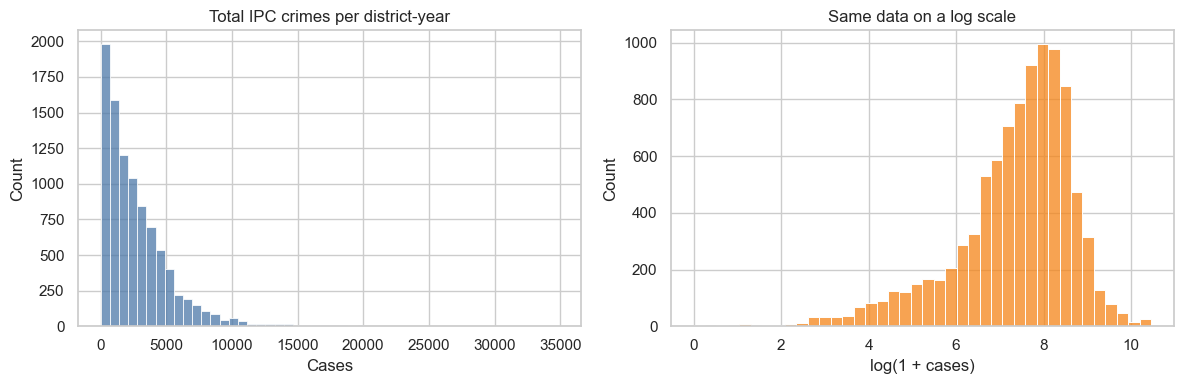

Insight: 63% of district-years are below the average, which confirms the long right tail.


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df[TOTAL_COL], bins=50, color="#4c78a8", ax=axes[0])
axes[0].set_title("Total IPC crimes per district-year")
axes[0].set_xlabel("Cases")

sns.histplot(np.log1p(df[TOTAL_COL]), bins=40, color="#f58518", ax=axes[1])
axes[1].set_title("Same data on a log scale")
axes[1].set_xlabel("log(1 + cases)")

plt.tight_layout()
fig.savefig(VISUALS_DIR / "02_total_distribution.png", dpi=150)
plt.show()

share_below_mean = (df[TOTAL_COL] < df[TOTAL_COL].mean()).mean() * 100
if share_below_mean > 60:
    print(f"Insight: {share_below_mean:.0f}% of district-years are below the average, which confirms the long right tail.")
else:
    print(f"Insight: {share_below_mean:.0f}% of district-years are below the average, so the data is not strongly skewed.")

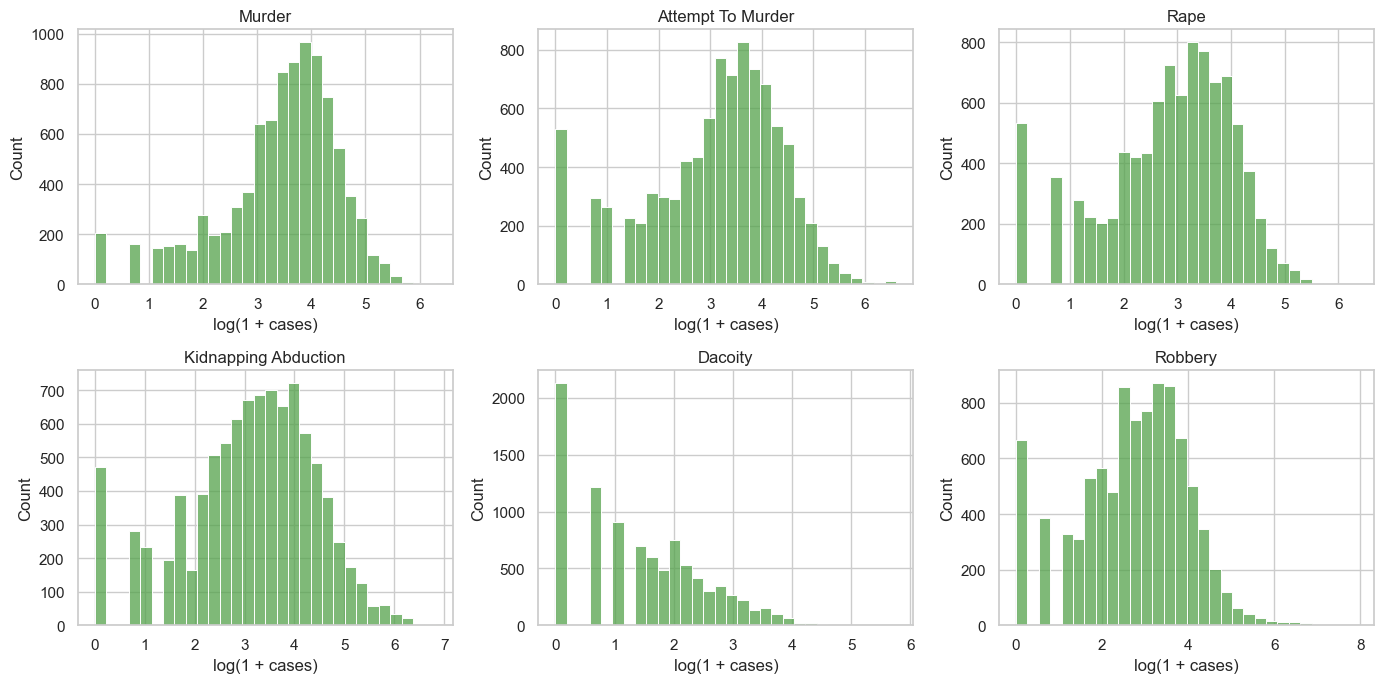

Percent of district-years with zero reported cases:
dacoity                 23%
robbery                  7%
attempt_to_murder        6%
rape                     6%
kidnapping_abduction     5%
murder                   2%


In [18]:
# Distribution of individual crime types (log scale)
show = MAIN_CRIMES[:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), show):
    sns.histplot(np.log1p(df[col]), bins=30, color="#54a24b", ax=ax)
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("log(1 + cases)")
for ax in axes.ravel()[len(show):]:
    ax.set_visible(False)
plt.tight_layout()
fig.savefig(VISUALS_DIR / "02_crime_distributions.png", dpi=150)
plt.show()

zero_share = (df[show] == 0).mean().mul(100).round(0).sort_values(ascending=False)
print("Percent of district-years with zero reported cases:")
print(zero_share.astype(int).astype(str).add("%").to_string())

## 4. Total crime over the years
Yearly national total with the percent change from the previous year.

In [19]:
national = state_year.groupby("year")[[TOTAL_COL] + MAIN_CRIMES].sum()

trend = national[[TOTAL_COL]].copy()
trend["change_from_previous_year_%"] = (trend[TOTAL_COL].pct_change() * 100).round(1)
display(trend)

first_year, last_year = trend.index.min(), trend.index.max()
peak_year, low_year = trend[TOTAL_COL].idxmax(), trend[TOTAL_COL].idxmin()
overall = (trend.loc[last_year, TOTAL_COL] / trend.loc[first_year, TOTAL_COL] - 1) * 100

print(f"Insight: total registered IPC crime went from {trend.loc[first_year, TOTAL_COL]:,.0f} in {first_year} "
      f"to {trend.loc[last_year, TOTAL_COL]:,.0f} in {last_year} ({overall:+.1f}%).")
print(f"Insight: the highest year is {peak_year} and the lowest is {low_year}.")

,total_ipc_crimes,change_from_previous_year_%
year,,
2001,1769308.0,NaN
2002,1780330.0,0.6
2003,1716120.0,-3.6
2004,1832010.0,6.8
2005,1822602.0,-0.5
2006,1878293.0,3.1
2007,1989673.0,5.9
2008,2093379.0,5.2
2009,2121345.0,1.3


Insight: total registered IPC crime went from 1,769,308 in 2001 to 2,647,722 in 2013 (+49.6%).
Insight: the highest year is 2013 and the lowest is 2003.


## 5. Which states report the most crime?
These are **counts, not rates**. Large states report more crime partly because they have more people. A per-lakh rate would need population data.

In [20]:
state_totals = state_year.groupby("state")[TOTAL_COL].sum().sort_values(ascending=False)
state_table = state_totals.to_frame("total_crimes")
state_table["share_percent"] = (state_totals / state_totals.sum() * 100).round(1)
state_table["cumulative_percent"] = state_table["share_percent"].cumsum().round(1)

print("Top 10 states/UTs:")
display(state_table.head(10))
print("Bottom 5 states/UTs:")
display(state_table.tail(5))

top = state_table.index[0]
print(f"Insight: {top} has the highest total ({state_table.loc[top, 'share_percent']}% of all registered crime).")
print(f"Insight: the top 5 states together account for {state_table['share_percent'].head(5).sum():.1f}% of the total.")

Top 10 states/UTs:


,total_crimes,share_percent,cumulative_percent
state,,,
Madhya Pradesh,2641223.0,9.9,9.9
Maharashtra,2507821.0,9.4,19.3
Tamil Nadu,2263755.0,8.5,27.8
Andhra Pradesh,2236996.0,8.4,36.2
Uttar Pradesh,2084519.0,7.8,44.0
Rajasthan,2052140.0,7.7,51.7
Karnataka,1617752.0,6.1,57.8
Kerala,1613793.0,6.1,63.9
Gujarat,1543210.0,5.8,69.7


Bottom 5 states/UTs:


,total_crimes,share_percent,cumulative_percent
state,,,
A & N Islands,9714.0,0.0,99.7
Sikkim,7851.0,0.0,99.7
D & N Haveli,4965.0,0.0,99.7
Daman & Diu,3194.0,0.0,99.7
Lakshadweep,783.0,0.0,99.7


Insight: Madhya Pradesh has the highest total (9.9% of all registered crime).
Insight: the top 5 states together account for 44.0% of the total.


## 6. Which crime types are most common, and which grew fastest?
**Reading the shares:** some crime heads include others (for example rape includes custodial rape), so the percentages do not add up to 100%.

In [21]:
type_totals = df[MAIN_CRIMES].sum().sort_values(ascending=False)
type_table = type_totals.to_frame("total_cases")
type_table["percent_of_total_ipc"] = (type_totals / df[TOTAL_COL].sum() * 100).round(1)
display(type_table)

top3 = type_table.index[:3].tolist()
print(f"Insight: the three most common crime types are {', '.join(c.replace('_', ' ') for c in top3)}.")

,total_cases,percent_of_total_ipc
theft,3873152.0,14.6
hurt_grevious_hurt,3706545.0,13.9
burglary,1221740.0,4.6
causing_death_by_negligence,1113381.0,4.2
cheating,874927.0,3.3
riots,847053.0,3.2
murder,435744.0,1.6
kidnapping_abduction,422318.0,1.6
attempt_to_murder,387394.0,1.5
robbery,280194.0,1.1


Insight: the three most common crime types are theft, hurt grevious hurt, burglary.


In [22]:
# Change between the first and last year for each main crime type
first_row, last_row = national.loc[first_year], national.loc[last_year]
usable = [c for c in MAIN_CRIMES if first_row[c] > 0 and last_row[c] > 0]
skipped = [c for c in MAIN_CRIMES if c not in usable]
if skipped:
    print(f"Left out (zero cases in {first_year} or {last_year}, possibly not reported that year): {skipped}\n")
growth = ((last_row[usable] / first_row[usable] - 1) * 100).sort_values(ascending=False).round(1)
growth_table = growth.to_frame(f"change_{first_year}_to_{last_year}_%")

print("Fastest growing:")
display(growth_table.head(5))
print("Slowest growing / declining:")
display(growth_table.tail(5))

print(f"Insight: {growth.index[0].replace('_', ' ')} grew the most ({growth.iloc[0]:+.1f}%) "
      f"and {growth.index[-1].replace('_', ' ')} grew the least ({growth.iloc[-1]:+.1f}%) between {first_year} and {last_year}.")
print("Note: growth can partly reflect better reporting or changed definitions, not only more crime.")

Fastest growing:


,change_2001_to_2013_%
kidnapping_abduction,191.1
cheating,140.0
rape,109.7
causing_death_by_negligence,95.0
robbery,60.4


Slowest growing / declining:


,change_2001_to_2013_%
burglary,3.2
riots,-5.4
murder,-8.3
arson,-11.2
dacoity,-26.2


Insight: kidnapping abduction grew the most (+191.1%) and dacoity grew the least (-26.2%) between 2001 and 2013.
Note: growth can partly reflect better reporting or changed definitions, not only more crime.


## 7. Districts with the highest average crime
District names repeat across states (for example Aurangabad), so districts are grouped by **state + district**.

In [23]:
district_avg = (
    df.groupby(["state", "district"])[TOTAL_COL].mean()
    .sort_values(ascending=False).head(10).round(0)
    .reset_index(name="average_ipc_crimes_per_year")
)
display(district_avg)

row = district_avg.iloc[0]
print(f"Insight: {row['district']} ({row['state']}) has the highest yearly average with {row['average_ipc_crimes_per_year']:,.0f} IPC cases.")

,state,district,average_ipc_crimes_per_year
0,Maharashtra,Mumbai Commr.,32189.0
1,Karnataka,Bangalore Commr.,29282.0
2,Maharashtra,Mumbai,28363.0
3,Rajasthan,Jaipur,19905.0
4,Gujarat,Ahmedabad Commr.,18405.0
5,Madhya Pradesh,Indore,17434.0
6,Andhra Pradesh,Hyderabad City,16868.0
7,Kerala,Ernakulam,15258.0
8,Andhra Pradesh,Cyberabad,14703.0
9,West Bengal,Kolkata,14211.0


Insight: Mumbai Commr. (Maharashtra) has the highest yearly average with 32,189 IPC cases.


## 8. Correlation between crime types
**Spearman** correlation is used because the data is heavily skewed. It compares rankings, so a few huge districts do not dominate. A value near +1 means districts that rank high in one crime also rank high in the other.

**Important:** most crime types are positively correlated mainly because **bigger districts have more of everything**. High correlation does not mean one crime causes another.

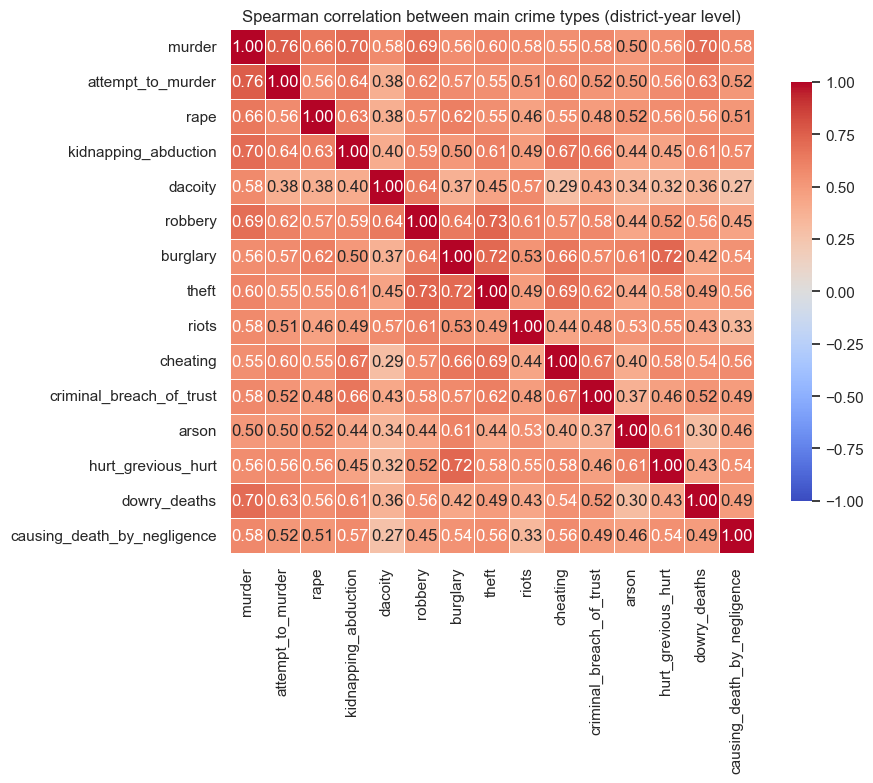

In [24]:
corr = df[MAIN_CRIMES].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Spearman correlation between main crime types (district-year level)")
plt.tight_layout()
fig.savefig(VISUALS_DIR / "02_correlation_heatmap.png", dpi=150)
plt.show()

In [25]:
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().dropna().sort_values(ascending=False)
pairs.index = [f"{a.replace('_', ' ')}  &  {b.replace('_', ' ')}" for a, b in pairs.index]

print("Most strongly related pairs:")
display(pairs.head(8).round(2).to_frame("spearman_corr"))
print("Least related pairs:")
display(pairs.tail(5).round(2).to_frame("spearman_corr"))

print(f"Insight: the strongest pair is {pairs.index[0]} ({pairs.iloc[0]:.2f}); the weakest is {pairs.index[-1]} ({pairs.iloc[-1]:.2f}).")
avg_corr = pairs.mean()
if avg_corr > 0.5:
    print(f"Insight: the average correlation across all pairs is {avg_corr:.2f}, which points to a strong shared 'district size' effect.")
else:
    print(f"Insight: the average correlation across all pairs is {avg_corr:.2f}, so crime types are only loosely related.")

Most strongly related pairs:


,spearman_corr
murder & attempt to murder,0.76
robbery & theft,0.73
burglary & hurt grevious hurt,0.72
burglary & theft,0.72
murder & dowry deaths,0.70
murder & kidnapping abduction,0.70
theft & cheating,0.69
murder & robbery,0.69


Least related pairs:


,spearman_corr
riots & causing death by negligence,0.33
dacoity & hurt grevious hurt,0.32
arson & dowry deaths,0.30
dacoity & cheating,0.29
dacoity & causing death by negligence,0.27


Insight: the strongest pair is murder  &  attempt to murder (0.76); the weakest is dacoity  &  causing death by negligence (0.27).
Insight: the average correlation across all pairs is 0.53, which points to a strong shared 'district size' effect.


## 9. Save the summary tables

In [26]:
trend.to_csv(PROCESSED_DIR / "eda_national_trend.csv")
state_table.to_csv(PROCESSED_DIR / "eda_state_ranking.csv")
type_table.to_csv(PROCESSED_DIR / "eda_crime_type_totals.csv")
print("Saved 3 summary tables in", PROCESSED_DIR)
print("Saved 3 charts in", VISUALS_DIR)

Saved 3 summary tables in /Users/mantavyagupta/crime-in-india-analysis/data/processed
Saved 3 charts in /Users/mantavyagupta/crime-in-india-analysis/visuals


## Summary of Part 2
| Topic | What was done |
|---|---|
| Coverage | checked states, districts and rows per year |
| Summary statistics | describe, skewness, mean vs median |
| Distributions | histograms, normal and log scale |
| Trend | yearly totals and percent change |
| States / districts | rankings and share of total |
| Crime types | totals, shares, growth between first and last year |
| Correlation | Spearman matrix, strongest and weakest pairs |

**Remember when writing your report:** these are registered counts, not rates, and a high correlation can come from district size.

**Next: Part 3, `03_visualizations.ipynb`** (10 charts including the India map).